In [2]:
!pip install -q omegaconf editdistance
!git clone -q https://github.com/Neuroprosthetics-Lab/nejm-brain-to-text

import sys, os, h5py, numpy as np, pandas as pd, torch, editdistance
import matplotlib.pyplot as plt
from omegaconf import OmegaConf
from tqdm import tqdm

sys.path.append("/kaggle/working/nejm-brain-to-text/model_training")
from rnn_model import GRUDecoder                 # the official model class
from data_augmentations import gauss_smooth      # the official input smoothing
from evaluate_model_helpers import LOGIT_TO_PHONEME

DATA_DIR = "/kaggle/input/competitions/brain-to-text-25"
SESSIONS_DIR = f"{DATA_DIR}/t15_copyTask_neuralData/hdf5_data_final"
CKPT_DIR = f"{DATA_DIR}/t15_pretrained_rnn_baseline/t15_pretrained_rnn_baseline/checkpoint"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

fatal: destination path 'nejm-brain-to-text' already exists and is not an empty directory.
Using: cuda


install, clone, import

In [3]:
args = OmegaConf.load(f"{CKPT_DIR}/args.yaml")
print(OmegaConf.to_yaml(args.model))   # the model's settings

model = GRUDecoder(
    neural_dim=args.model.n_input_features,
    n_units=args.model.n_units,
    n_days=len(args.dataset.sessions),
    n_classes=args.dataset.n_classes,
    rnn_dropout=args.model.rnn_dropout,
    input_dropout=args.model.input_network.input_layer_dropout,
    n_layers=args.model.n_layers,
    patch_size=args.model.patch_size,
    patch_stride=args.model.patch_stride,
)

ckpt = torch.load(f"{CKPT_DIR}/best_checkpoint", map_location="cpu", weights_only=False)
state = {k.replace("module.", "").replace("_orig_mod.", ""): v
         for k, v in ckpt["model_state_dict"].items()}   # strip prefixes added during multi-GPU training
model.load_state_dict(state)
model.to(device).eval()   # eval() turns off dropout

print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

n_input_features: 512
n_units: 768
rnn_dropout: 0.4
rnn_trainable: true
n_layers: 5
bidirectional: false
patch_size: 14
patch_stride: 4
input_network:
  n_input_layers: 1
  input_layer_sizes:
  - 512
  input_trainable: true
  input_layer_dropout: 0.2

44.3M parameters


build the model and load the trained weights

In [4]:
sessions = list(args.dataset.sessions)   # order defines each session's day_idx
val = []
for day_idx, s in enumerate(sessions):
    p = f"{SESSIONS_DIR}/{s}/data_val.hdf5"
    if not os.path.exists(p):
        continue                          # the 4 training-only sessions you found in step 2
    with h5py.File(p, "r") as h:
        for k in h.keys():
            g = h[k]
            val.append(dict(
                session=s, day_idx=day_idx,
                x=g["input_features"][:],
                true=list(g["seq_class_ids"][:g.attrs["seq_len"]]),
                sentence=g.attrs["sentence_label"],
            ))
print(len(val), "validation trials")   # should be 1,426, matching your step 2 count

1426 validation trials


load the validation set

In [5]:
smooth = args.dataset.data_transforms

def predict(x, day_idx):
    x = torch.tensor(x[None], dtype=torch.float32, device=device)   # add batch dimension
    x = gauss_smooth(inputs=x, device=device,
                     smooth_kernel_std=smooth.smooth_kernel_std,
                     smooth_kernel_size=smooth.smooth_kernel_size,
                     padding="valid")                                 # same smoothing as training
    with torch.no_grad():
        logits = model(x, torch.tensor([day_idx], device=device))
    return logits[0].float().cpu().numpy()                            # (time steps, 41 classes)

def greedy_ctc(logits):
    out, prev = [], -1
    for i in logits.argmax(-1):          # most likely class at each step
        if i != prev and i != 0:         # merge repeats, then drop blanks (class 0)
            out.append(int(i))
        prev = i
    return out

prediction and greedy CTC (Connectionist Temporal Classification: machine learning loss function used to map input sequences to output sequences of different lengths (like speech-to-text) without requiring the data to be aligned or labeled frame-by-frame).

In [6]:
total_err = total_len = 0
for t in tqdm(val):
    t["pred"] = greedy_ctc(predict(t["x"], t["day_idx"]))
    t["err"] = editdistance.eval(t["pred"], t["true"])
    total_err += t["err"]
    total_len += len(t["true"])
print(f"Validation PER: {100 * total_err / total_len:.2f}%")

100%|██████████| 1426/1426 [01:35<00:00, 14.93it/s]

Validation PER: 10.19%


score it

In [7]:
show = lambda ids: " ".join(LOGIT_TO_PHONEME[i] for i in ids)
for t in val[:5]:
    print("SENTENCE:", t["sentence"])
    print("TRUE:    ", show(t["true"]))
    print("PRED:    ", show(t["pred"]))
    print(f"errors: {t['err']} / {len(t['true'])}\n")

SENTENCE: You can see the code at this point as well.
TRUE:     Y UW  |  K AE N  |  S IY  |  DH AH  |  K OW D  |  AE T  |  DH IH S  |  P OY N T  |  AE Z  |  W EH L  | 
PRED:     Y UW  |  K AE N  |  S IY  |  DH AH  |  K OW D  |  AE T  |  DH IH S  |  P OY N T  |  AE Z  |  W IH L  | 
errors: 1 / 36

SENTENCE: How does it keep the cost down?
TRUE:     HH AW  |  D AH Z  |  IH T  |  K IY P  |  DH AH  |  K AA S T  |  D AW N  | 
PRED:     HH AW  |  D AH S  |  IH T  |  K IY P  |  DH AH  |  K AA S T  |  T AW N T  | 
errors: 3 / 26

SENTENCE: Not too controversial.
TRUE:     N AA T  |  T UW  |  K AA N T R AH V ER SH AH L  | 
PRED:     N AA T  |  T UW  |  K AE N CH R UW F UW SH AH L  | 
errors: 5 / 19

SENTENCE: The jury and a judge work together on it.
TRUE:     DH AH  |  JH UH R IY  |  AH N D  |  AH  |  JH AH JH  |  W ER K  |  T AH G EH DH ER  |  AA N  |  IH T  | 
PRED:     DH AH  |  JH UH R IY  |  AH N  |  AH  |  CH AH S T  |  W ER K  |  T AH G EH DH ER  |  AA N  |  IH T  | 
errors: 4 / 35

SEN

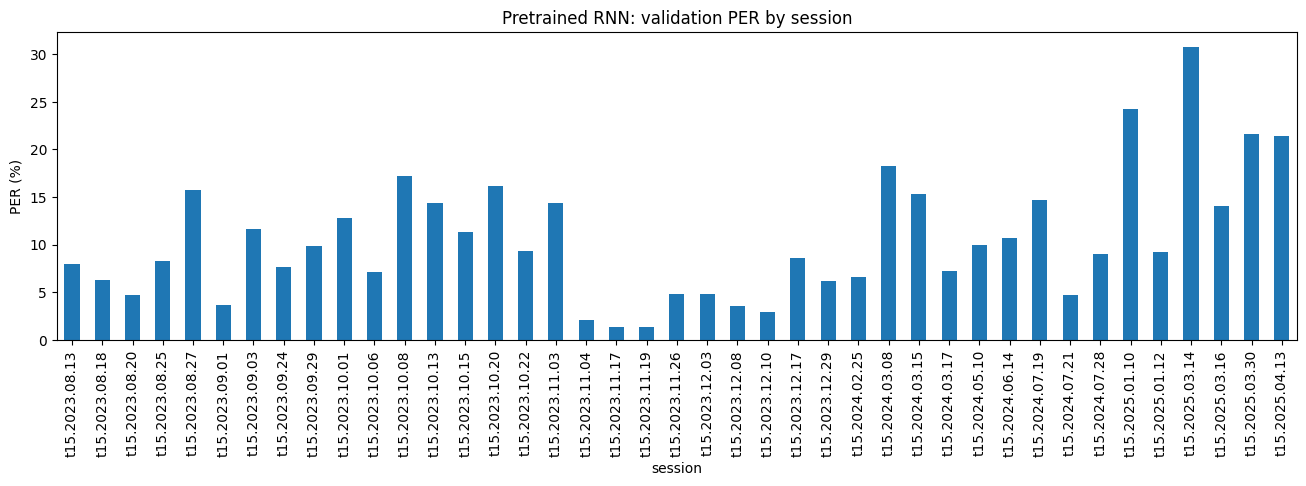

In [8]:
d = pd.DataFrame([(t["session"], t["err"], len(t["true"])) for t in val],
                 columns=["session", "err", "n"]).groupby("session").sum()
(100 * d.err / d.n).plot(kind="bar", figsize=(16, 4))
plt.ylabel("PER (%)"); plt.title("Pretrained RNN: validation PER by session"); plt.show()